1. Load:

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Read titanic.csv. If the file is not here, download it once and save it.
# (This is try / except from Class 12!)
try:
    df = pd.read_csv("tips.csv")
except FileNotFoundError:
    sns.load_dataset("tips").to_csv("tips.csv", index=False)   # needs internet
    df = pd.read_csv("tips.csv")


df.head()


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


Step:2 Inspect:

In [6]:
print(df.shape)

(244, 7)


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    str    
 3   smoker      244 non-null    str    
 4   day         244 non-null    str    
 5   time        244 non-null    str    
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), str(4)
memory usage: 13.5 KB


In [8]:
df.describe().round(1)

,total_bill,tip,size
count,244.0,244.0,244.0
mean,19.8,3.0,2.6
std,8.9,1.4,1.0
min,3.1,1.0,1.0
25%,13.3,2.0,2.0
50%,17.8,2.9,2.0
75%,24.1,3.6,3.0
max,50.8,10.0,6.0


In [9]:
df.isna().sum()

total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

In [11]:
print(df["sex"].value_counts())

sex
Male      157
Female     87
Name: count, dtype: int64


Step 3 : Clean
in this we have a code for filling null values and one for making new column

In [11]:
import numpy as np
import pandas as pd

# Reload df to ensure clean starting columns ('total_bill', 'tip', 'sex', etc.)
df = pd.read_csv("tips.csv")

# Clean & Make New Columns safely
df["total_amount"] = df["total_bill"] + df["tip"]
df["tip_pct"] = (df["tip"] / df["total_bill"]) * 100
df["bill_per_person"] = df["total_bill"] / df["size"]

# Handle gender column whether it's named 'sex' or 'gender'
gender_col = "sex" if "sex" in df.columns else "gender"
df["is_female"] = np.where(df[gender_col] == "Female", 1, 0)

# Preview the result
df.head()

,total_bill,tip,sex,smoker,day,time,size,total_amount,tip_pct,bill_per_person,is_female
0,16.99,1.01,Female,No,Sun,Dinner,2,18.00,5.944673,8.495000,1
1,10.34,1.66,Male,No,Sun,Dinner,3,12.00,16.054159,3.446667,0
2,21.01,3.50,Male,No,Sun,Dinner,3,24.51,16.658734,7.003333,0
3,23.68,3.31,Male,No,Sun,Dinner,2,26.99,13.978041,11.840000,0
4,24.59,3.61,Female,No,Sun,Dinner,4,28.20,14.680765,6.147500,1


Step 4: Distribution

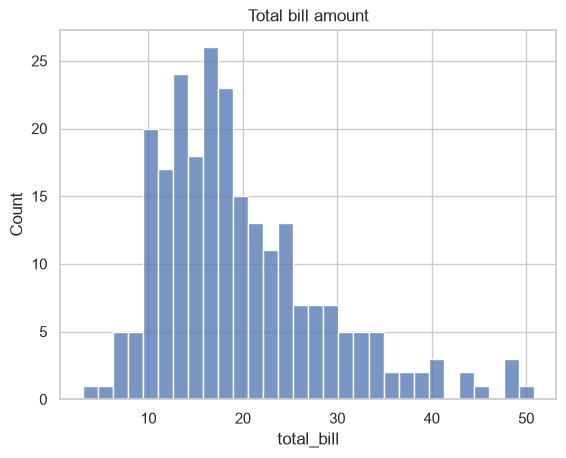

In [13]:
sns.histplot(data=df, x="total_bill", bins=30)
plt.title("Total bill amount")
plt.show()

# hue="time"

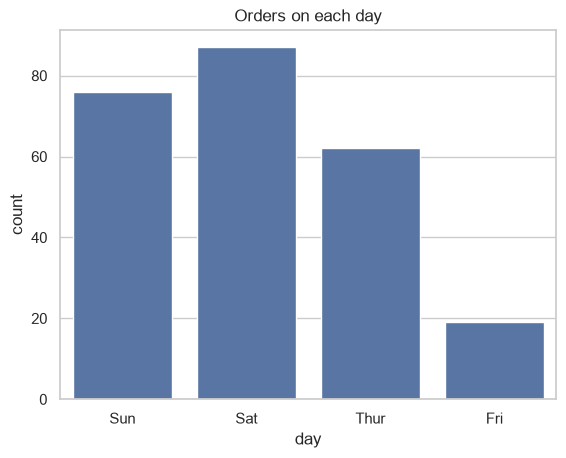

In [ ]:
#Step 4b: Outliers
sns.countplot(data=df, x="day")
plt.title("Orders on each day")
plt.show()

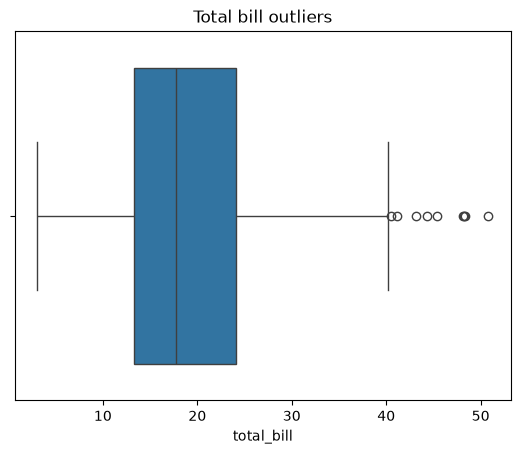

In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the dataset first
df = pd.read_csv("tips.csv")

# Now run the boxplot
sns.boxplot(data=df, x="total_bill")
plt.title("Total bill outliers")
plt.show()

In [16]:
q1 = df["total_bill"].quantile(0.25)
q3 = df["total_bill"].quantile(0.75)
iqr = q3 - q1
high = q3 + 1.5 * iqr

print("Q1:", q1, " Q3:", q3, " IQR:", round(iqr, 1))
print("Above", round(high, 1), "is an outlier")

outliers = df[df["total_bill"] > high]
print("Number of outliers:", len(outliers))
outliers.sort_values("total_bill", ascending=False).head()

Q1: 13.3475  Q3: 24.127499999999998  IQR: 10.8
Above 40.3 is an outlier
Number of outliers: 9


,total_bill,tip,sex,smoker,day,time,size,total_amount
170,50.81,10.00,Male,Yes,Sat,Dinner,3,60.81
212,48.33,9.00,Male,No,Sat,Dinner,4,57.33
59,48.27,6.73,Male,No,Sat,Dinner,4,55.00
156,48.17,5.00,Male,No,Sun,Dinner,6,53.17
182,45.35,3.50,Male,Yes,Sun,Dinner,3,48.85


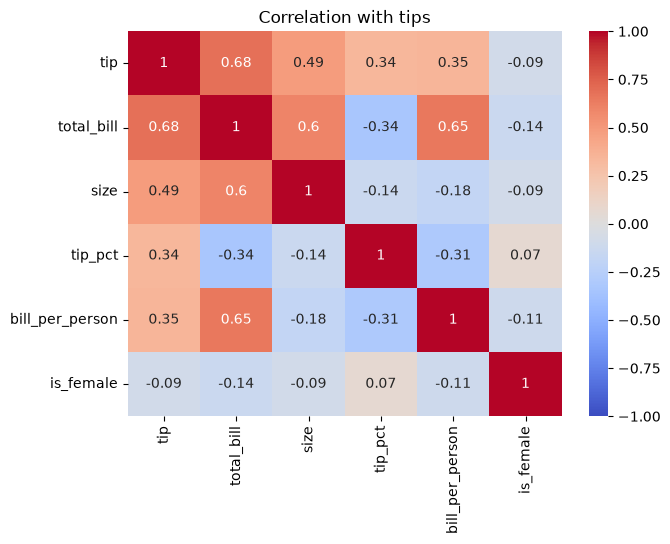

In [12]:
#Step 4c: Relations (Heatmap)
cols = ["tip", "total_bill", "size", "tip_pct", "bill_per_person", "is_female"]

plt.figure(figsize=(7, 5))
sns.heatmap(df[cols].corr().round(2), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation with tips")
plt.show()

Step :5

In [ ]:

group_col = "gender" if "gender" in df.columns else "sex"

print("--- Overall Statistics ---")
print("Average Total Bill: $", round(df["total_bill"].mean(), 2))
print("Average Tip Amount: $", round(df["tip"].mean(), 2))
print("Average Tip Percentage: ", round(df["tip_pct"].mean(), 2), "%\n")

print("--- Average Tip by Group ---")
print(df.groupby(group_col)["tip"].mean().round(2))

--- Overall Statistics ---
Average Total Bill: $ 19.79
Average Tip Amount: $ 3.0
Average Tip Percentage:  16.08 %

--- Average Tip by Group ---
sex
Female    2.83
Male      3.09
Name: tip, dtype: float64
